# 08 The figures of the main report

The figures of `docs/report.md`. Part 1 (the post-operations analysis model, the sections before Part 2): the
leaderboard RMSE of every scored upload by version, the stages of the work that produced the large steps, the board
checks of the operational models, which belong to another model family, and a waterfall of the best score's change by
stage, coloured by the tier of what each stage added (fig08_04). The report calls the scored model the post-operations
analysis model, because the challenge's rationale names post-operations analysis as a use of a taxi-out model; the
code, the configurations and the supporting documents call it the challenge model, and the `family` column below
keeps the value `challenge`. Part 2 (the operational models, the last sections): the moments of prediction with the
data each can read, and the scores per moment beside the post-operations models.

**Input and output.**
- `submissions/uploads.csv` is the upload log of the upload tool, which is not part of this repository: one row per
  upload, with the object, the run, the scorer's status and the score. It is gitignored.
- The notebook writes a tracked copy, `docs/board_history.csv`, with the columns `version, object, run_id, status,
  score, uploaded_at_utc, family`. Where the log is absent (a fresh clone), it reads that copy instead, checks the
  families against the rules below and leaves the copy unchanged.
- The board is the live leaderboard's RMSE over the 344,841 departures of January and July 2026 (`used_pairs` on every
  scored upload). It ranks a team by its best upload.

**The families** (column `family`). Rules on the run name and the status, checked against the uploads that the
findings name:

| family | rule | uploads |
|---|---|---|
| `challenge` | every other upload | the post-operations model's scored uploads, v2-v71 without v26 and v68 (v56 was never uploaded) |
| `operational` | run name starts with `op_` or `board_op_` | the operational models' board checks: v68, the H1 rung R4 of the operational ladder (findings 10.27), and v75-v77, v79-v82, v84 and v85, the January and July rows of the operational candidates' final-set files (findings 10.35-10.37) |
| `final-file` | run name starts with `final_v70`, or the object is the team's `_final.parquet` | the post-operations model on the final release (findings 10.34): v73 = its January and July rows; v72, v74, v78, v83 = the full file of January, February, June and July 2026; the team's `_final.parquet` (14 October, no version) = the final submission, accepted without a score |
| `rejected` | status `Rejected` | refused by the scorer's daily limit of five uploads (v26, the first v37, v85 of 13 October) |

No model is trained and no data frame is read. Each cell prints the numbers it draws.

In [1]:
import sys; sys.path.insert(0, ".")
import paper_style as ps; ps.setup()
from prc import paths
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D

pd.set_option("display.width", 200, "display.max_columns", 20, "display.max_rows", 120)

LOG = paths.SUBMISSIONS / "uploads.csv"                   # the upload tool's log (gitignored; not in this repository)
COPY = paths.ROOT / "docs" / "board_history.csv"       # its tracked copy, written below
COLUMNS = ["version", "object", "run_id", "status", "score", "uploaded_at_utc", "family"]
SOURCE = LOG if LOG.exists() else COPY
B = pd.read_csv(SOURCE)
B["_t"] = pd.to_datetime(B["uploaded_at_utc"], utc=True)
B = B.sort_values("_t", kind="mergesort").reset_index(drop=True)          # upload order
B["version"] = pd.to_numeric(B["object"].str.extract(r"_v(\d+)\.parquet$", expand=False),
                             errors="coerce").astype("Int64")             # NA for the team's _final.parquet
run_name = B["run_id"].astype(str).str.split("__").str[1].fillna("")
family = np.select(
    [B["status"].eq("Rejected").to_numpy(dtype=bool),
     (B["object"].str.endswith("_final.parquet") | run_name.str.startswith("final_v70")).to_numpy(dtype=bool),
     (run_name.str.startswith("op_") | run_name.str.startswith("board_op_")).to_numpy(dtype=bool)],
    ["rejected", "final-file", "operational"], default="challenge")
if SOURCE == COPY:
    assert (B["family"].to_numpy() == family).all(), "the tracked copy's families differ from the rules"
B["family"] = family

# the rules reproduce the uploads the findings name (sections 1, 9.20, 10.27, 10.34-10.36)
KNOWN = {"operational": {68, 75, 76, 77, 79, 80, 81, 82, 84, 85}, "final-file": {72, 73, 74, 78, 83}, "rejected": {26, 37, 85}}
for fam, vs in KNOWN.items():
    got = set(B.loc[B["family"].eq(fam), "version"].dropna().astype(int))
    assert vs <= got, f"{fam}: {sorted(vs - got)} not classified as {fam}"
# every rejected upload was the sixth or later of its UTC day (scored and failed uploads count; findings 9.20, 10.35)
day = B["_t"].dt.floor("D")
for i in B.index[B["status"].eq("Rejected")]:
    before = int(((day == day[i]) & (B.index < i) & B["status"].isin(["Succeeded", "Failed"])).sum())
    assert before >= 5, f"v{B.at[i, 'version']} was rejected after {before} uploads of its day"
    print(f"v{B.at[i, 'version']} rejected at {B.at[i, 'uploaded_at_utc']}: upload {before + 1} of its UTC day")

if SOURCE == LOG:
    assert (B.loc[B["score"].notna(), "used_pairs"] == 344_841).all(), "a score over another row count"
    B[COLUMNS].to_csv(COPY, index=False, lineterminator="\n")
print(f"source: {SOURCE.relative_to(paths.ROOT).as_posix()}; tracked copy: {COPY.relative_to(paths.ROOT).as_posix()} "
      f"({'written' if SOURCE == LOG else 'read'}, {len(B)} uploads)")
print(pd.crosstab(B["family"], B["status"], margins=True).to_string())

S = B[B["score"].notna() & B["version"].notna()].copy()                   # scored uploads with a version
S["v"] = S["version"].astype(int)
assert S["v"].is_unique, "a version scored twice"
board = S.set_index("v")["score"]
CH = S[S["family"].eq("challenge")].sort_values("v").reset_index(drop=True)
CH["best"] = CH["score"].cummin()                                         # best so far, in version order
OPS = S[S["family"].eq("operational")].set_index("v")["score"]
FF = S[S["family"].eq("final-file")].set_index("v")["score"]              # the final file's scored subsets (v73)
NOSCORE = B[B["score"].isna() & B["version"].notna()]
VBEST = int(CH.loc[CH["score"].idxmin(), "v"])
seq = S[S["family"].isin(["challenge", "final-file"])].copy()             # upload order
seq["best_before"] = seq["score"].cummin().shift()
seq["delta"] = seq["score"] - seq["best_before"]                         # change against the best before the upload
dlt = seq.set_index("v")["delta"]
print(f"scored uploads {len(S)}: challenge {len(CH)} (v{CH.v.min()}-v{CH.v.max()}), final file "
      f"{', '.join(f'v{v}' for v in FF.index)}, operational {len(OPS)}; not scored "
      f"{', '.join(f'v{v} ({s})' for v, s in zip(NOSCORE['version'], NOSCORE['status']))}")
print(f"first v{CH.v.iloc[0]} {CH.score.iloc[0]:.4f}; best v{VBEST} {board[VBEST]:.4f}; "
      f"versions never uploaded: {sorted(set(range(2, int(B.version.max()) + 1)) - set(B.version.dropna().astype(int)))}")
print(seq[["v", "family", "uploaded_at_utc", "score", "best_before", "delta"]].round(4).to_string(index=False))

v26 rejected at 2026-09-29T22:35:05+00:00: upload 6 of its UTC day
v37 rejected at 2026-10-01T22:03:53+00:00: upload 6 of its UTC day
v85 rejected at 2026-10-13T15:31:29+00:00: upload 6 of its UTC day
source: submissions/uploads.csv; tracked copy: docs/board_history.csv (written, 86 uploads)
status       Failed  Rejected  Succeeded  All
family                                       
challenge         0         0         67   67
final-file        4         0          2    6
operational       0         0         10   10
rejected          0         3          0    3
All               4         3         79   86
scored uploads 78: challenge 67 (v2-v71), final file v73, operational 10; not scored v26 (Rejected), v37 (Rejected), v72 (Failed), v74 (Failed), v78 (Failed), v83 (Failed), v85 (Rejected)
first v2 422.3732; best v70 220.3396; versions never uploaded: [56]
 v     family           uploaded_at_utc    score  best_before    delta
 2  challenge 2026-09-15T14:58:45+00:00 422.3732          

## The stages of the work

The stage boundaries follow the findings: the upload that introduced each change, and the uploads that tuned it. The
gain of a stage is the change of the best score over the stage; its share is taken of the total gain from the first
upload (v2) to the best (v70), in RMSE and in MSE (the board's squared error). The cell below prints them.

| stage | versions | what changed | findings |
|---|---|---|---|
| A | v2 | raw target, one CatBoost per airport, refit on all twelve months | 1, 3 |
| B | v3-v8 | stale records: takeoff − schedule as a residual base (v3), the regime mixture (v4), the wrong-date probe (v5) and the wrong-date rows out of the fit (v6), seeds (v7, v8) | 1-3 |
| C | v9-v30 | five context blocks (v9); the mixture from 30 min deltas, winter weather and ERA5 (v10); time-position columns, live state, the block screen, classifier and month weights (v11-v18); trimming and the board's seed noise (v19-v24); wide blends (v25-v30) | 7.5b, 8.3, 9.5-9.20 |
| D | v31 | v29 clipped to the NM join window | 10.3 |
| E | v32 | window-aware members and stack, in-window estimate, linked-row regime exclusion: the last upload without position data | 10.5, 10.7 |
| F | v33-v44 | the ADS-B second stage on the flight's own track, from 26 to all 62 holdout days; four feature sets; the direct formulation | 10.6-10.11 |
| G | v45-v60 | the stage on more training days (120, 232, 350), averaging and re-tuning, the forced-long shift | 10.15-10.21 |
| H | v61-v71 | base members trained longer, the stage refitted on them, the Istanbul partner-runway specialist, depth-9 retrains | 10.22-10.30 |
| I | v72-v83 | the final file (v73 its January and July rows) | 10.34, 10.36 |

In [2]:
STAGES = [("A", 2, 2), ("B", 3, 8), ("C", 9, 30), ("D", 31, 31), ("E", 32, 32), ("F", 33, 44), ("G", 45, 60),
          ("H", 61, 71)]
BEST_AT = CH.set_index("v")["best"]


def best_upto(v):
    return float(BEST_AT[BEST_AT.index <= v].iloc[-1])


START, FINAL_BEST = float(CH["score"].iloc[0]), float(CH["score"].min())
TOT, TOT_MSE = START - FINAL_BEST, START ** 2 - FINAL_BEST ** 2
new_best = (seq["delta"] < 0).set_axis(seq["v"])
rows, prev = [], None
for s, a, b in STAGES:
    end = best_upto(b)
    inside = CH[(CH.v >= a) & (CH.v <= b)]
    r = dict(stage=s, versions=f"v{a}" if a == b else f"v{a}-v{b}", scored=len(inside),
             new_bests=int(new_best.reindex(inside.v).fillna(False).sum()) + (1 if prev is None else 0), best=end)
    if prev is not None:
        r.update(gain=end - prev, share_rmse=100 * (prev - end) / TOT, share_mse=100 * (prev ** 2 - end ** 2) / TOT_MSE)
    rows.append(r)
    prev = end
ST = pd.DataFrame(rows).set_index("stage")
gain, share = ST["gain"], ST["share_rmse"] / 100
print(ST.round({"best": 4, "gain": 2, "share_rmse": 1, "share_mse": 1}).to_string())
print(f"total v{CH.v.iloc[0]} -> v{VBEST}: {FINAL_BEST - START:+.4f} s of RMSE, {FINAL_BEST ** 2 - START ** 2:+,.0f} of MSE")
late = CH[(CH.v > 44) & (CH.v <= 71)]
g_late = best_upto(71) - best_upto(44)
print(f"after v44: {len(late)} challenge uploads (v45-v71), best {best_upto(44):.4f} -> {best_upto(71):.4f} = "
      f"{g_late:+.4f} s ({100 * -g_late / TOT:.2f} % of the RMSE gain, {100 * (best_upto(44) ** 2 - best_upto(71) ** 2) / TOT_MSE:.2f} % of the MSE gain)")
for v, sc in FF.items():
    print(f"v{v} (final file, January and July rows) {sc:.4f}: {sc - board[VBEST]:+.4f} against v{VBEST}")
print("operational board checks:", {f"v{v}": round(float(sc), 2) for v, sc in OPS.items()},
      f"| lowest {OPS.min():.2f}, against the challenge best {board[VBEST]:.2f}: {OPS.min() - board[VBEST]:+.2f}")

      versions  scored  new_bests      best    gain  share_rmse  share_mse
stage                                                                     
A           v2       1          1  422.3732     NaN         NaN        NaN
B        v3-v8       6          4  317.0143 -105.36        52.1       60.0
C       v9-v30      21          9  303.0164  -14.00         6.9        6.7
D          v31       1          1  263.1671  -39.85        19.7       17.4
E          v32       1          1  260.7228   -2.44         1.2        1.0
F      v33-v44      12         11  223.0867  -37.64        18.6       14.0
G      v45-v60      15         12  220.6768   -2.41         1.2        0.8
H      v61-v71      10          4  220.3396   -0.34         0.2        0.1
total v2 -> v70: -202.0336 s of RMSE, -129,850 of MSE
after v44: 25 challenge uploads (v45-v71), best 223.0867 -> 220.3396 = -2.7471 s (1.36 % of the RMSE gain, 0.94 % of the MSE gain)
v73 (final file, January and July rows) 220.3930: +0.0534 against

## Figure 1. The board RMSE of every upload

The x axis is the upload version. One broken y axis carries two model families on the same board:
- **(a) The operational models.** They predict before the off-block: H1 15 min before the last filed off-block, and 3 h
  and 24 h before the schedule. They have no regime mixture for the stale records, no join-window clip and no ADS-B, and
  none was tuned to the board. v68 is the H1 rung R4 of the ladder (findings 10.27); v75-v85 are the January and July
  rows of the candidates' final-set files, uploaded as checks of those files (findings 10.35, 10.36). Marker shapes
  give the decision moment and the output. v80 and v85 read the traffic after the H1 anchor, a stand-in for planning
  data (tier F, an upper bound).
- **(b) The post-operations model.** Every scored upload, the best score so far (the board ranks a team by its best
  upload) and the best, v70. v73 is the final file's January and July rows. Crosses on the axis mark uploads without a
  score: the daily limit (v26, the first v37, the first v85 on 13 October) and the full final file (v72, v74, v78,
  v83). Shaded spans alternate between the stages of the table above. The texts give each stage's gain and its share
  of the total gain from v2 to v70.
- **(c) v44-v73 enlarged.** The late steps are tenths of a second. Each number in parentheses is the upload's change
  against the best score before it, in upload order. The board's own noise is about ±0.03 s (findings 10.15).

The share of the scored rows that the ADS-B stage corrects is not in the upload log. It comes from
`stack.n_rank_corrected` in the runs' `metrics.json` (97,960, 162,502 and 237,291 of 344,841 rows for v33, v34 and v35;
findings 10.7) and is written into the cell as a constant.

ADS-B stage, share of the scored rows corrected: {'v33': '28.4 %', 'v34': '47.1 %', 'v35': '68.8 %'}
labelled steps (change against the best before): {'v3': -92.8668, 'v6': -10.949, 'v46': -0.9751, 'v48': -0.4416, 'v57': -0.1557, 'v58': 0.794, 'v61': -0.0506, 'v62': -0.0506, 'v64': 0.1056, 'v66': 0.0727, 'v69': -0.1215, 'v70': -0.1145, 'v73': 0.0534}


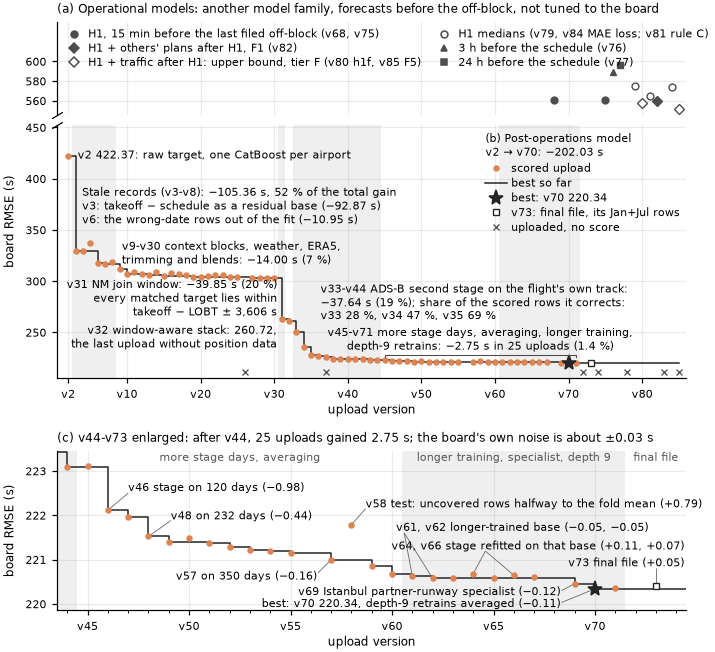

In [3]:
CORRECTED_2026 = {33: 97_960, 34: 162_502, 35: 237_291}   # stack.n_rank_corrected, metrics.json of the v33-v35 runs
N_RANK = 344_841                                           # scored departures, January and July 2026


def sg(x, nd=2):
    # signed number with a typographic minus
    return f"{x:+.{nd}f}".replace("-", "−")


print("ADS-B stage, share of the scored rows corrected:",
      {f"v{v}": f"{100 * n / N_RANK:.1f} %" for v, n in CORRECTED_2026.items()})
print("labelled steps (change against the best before):",
      {f"v{v}": round(float(dlt[v]), 4) for v in (3, 6, 46, 48, 57, 58, 61, 62, 64, 66, 69, VBEST, *FF.index)})

W = ps.WIDTH
TOP, HA, GAP_AB, HB, GAP_BC, HC, BOT = 0.30, 0.85, 0.09, 2.30, 0.66, 1.45, 0.42   # inches
H = TOP + HA + GAP_AB + HB + GAP_BC + HC + BOT
L, R = 0.52, 0.06


def box(top, h):
    return [L / W, 1 - (top + h) / H, 1 - (L + R) / W, h / H]


fig = plt.figure(figsize=(W, H))
axA = fig.add_axes(box(TOP, HA))
axB = fig.add_axes(box(TOP + HA + GAP_AB, HB), sharex=axA)
axC = fig.add_axes(box(TOP + HA + GAP_AB + HB + GAP_BC, HC))
VMAX = int(B["version"].max())
XMIN, XMAX = 0.5, VMAX + 1.0
SHADE, LEADER, C_OP, INK = "#EFEFEF", "0.45", "#4D4D4D", "#252525"
TXT = dict(fontsize=7, va="center", zorder=6)


def shade(ax):
    for i, (s, a, b) in enumerate(STAGES):
        if i % 2:
            ax.axvspan(a - 0.5, b + 0.5, color=SHADE, lw=0, zorder=0)


def challenge(ax, rug=True):
    ax.plot(CH.v, CH.score, "o", ms=3.2, color=ps.C_2026, zorder=3, label="scored upload")
    ax.step(np.r_[CH.v.to_numpy(), VMAX], np.r_[CH.best.to_numpy(), CH.best.iloc[-1]], where="post", color=INK,
            lw=1.0, zorder=2, label="best so far")
    ax.plot(VBEST, board[VBEST], "*", ms=10, color=INK, zorder=4, label=f"best: v{VBEST} {board[VBEST]:.2f}")
    for v, sc in FF.items():
        ax.plot(v, sc, "s", ms=4.2, mfc="white", mec=INK, mew=0.9, zorder=4, label=f"v{v}: final file, its Jan+Jul rows")
    if rug:
        tr = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
        ax.plot(NOSCORE["version"].astype(int), np.full(len(NOSCORE), 0.025), "x", ms=3.5, mew=0.9, color="0.35",
                transform=tr, zorder=4, label="uploaded, no score")


# (a) the operational board checks: marker = decision moment and output
OP_STYLE = {68: ("o", True), 75: ("o", True), 82: ("D", True), 80: ("D", False), 85: ("D", False), 79: ("o", False),
            81: ("o", False), 84: ("o", False), 76: ("^", True), 77: ("s", True)}
for v, sc in OPS.items():
    mk, filled = OP_STYLE.get(v, ("P", True))
    axA.plot(v, sc, mk, ms=4.5, mfc=C_OP if filled else "white", mec=C_OP, mew=0.9, zorder=3)
OP_LEG = [("o", True, "H1, 15 min before the last filed off-block (v68, v75)"),
          ("D", True, "H1 + others' plans after H1, F1 (v82)"),
          ("D", False, "H1 + traffic after H1: upper bound, tier F (v80 h1f, v85 F5)"),
          ("o", False, "H1 medians (v79, v84 MAE loss; v81 rule C)"),
          ("^", True, "3 h before the schedule (v76)"),
          ("s", True, "24 h before the schedule (v77)")]
axA.legend([Line2D([], [], ls="none", marker=mk, ms=4.5 if mk != "D" else 4.2, mfc=C_OP if f else "white", mec=C_OP)
            for mk, f, _ in OP_LEG], [t for _, _, t in OP_LEG], loc="upper left", ncols=2, fontsize=7, frameon=False,
           handletextpad=0.3, columnspacing=1.2, borderaxespad=0.2, labelspacing=0.25)
axA.set_ylim(545, 640)
axA.set_yticks([560, 580, 600])
axA.spines["bottom"].set_visible(False)
axA.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
axA.set_title("(a) Operational models: another model family, forecasts before the off-block, not tuned to the board",
              loc="left", fontsize=8)

# (b) the post-operations model (the family "challenge")
shade(axB)
challenge(axB)
axB.set_xlim(XMIN, XMAX)
axB.set_ylim(205, 452)
axB.set_yticks([250, 300, 350, 400, 450])
axB.set_ylabel("board RMSE (s)")
axB.yaxis.set_label_coords(-0.065, 0.62)
xt = [2] + list(range(10, VMAX + 1, 10))
axB.set_xticks(xt, [f"v{v}" for v in xt])
axB.set_xlabel("upload version", labelpad=2)
axB.text(3.3, board[2], f"v2 {board[2]:.2f}: raw target, one CatBoost per airport", ha="left", **TXT)
axB.text(3.9, 373, f"Stale records (v3-v8): {sg(gain['B'])} s, {100 * share['B']:.0f} % of the total gain\n"
         f"v3: takeoff − schedule as a residual base ({sg(dlt[3])} s)\n"
         f"v6: the wrong-date rows out of the fit ({sg(dlt[6])} s)", ha="left", **TXT)
axB.text(9.3, 327, f"v9-v30 context blocks, weather, ERA5,\ntrimming and blends: {sg(gain['C'])} s "
         f"({100 * share['C']:.0f} %)", ha="left", **TXT)
axB.text(30.4, 283, f"v31 NM join window: {sg(gain['D'])} s ({100 * share['D']:.0f} %)\n"
         "every matched target lies within\ntakeoff − LOBT ± 3,606 s", ha="right", **TXT)
axB.text(30.4, 245, f"v32 window-aware stack: {board[32]:.2f},\nthe last upload without position data", ha="right",
         **TXT)
axB.text(36.3, 279, f"v33-v44 ADS-B second stage on the flight's own track:\n{sg(gain['F'])} s "
         f"({100 * share['F']:.0f} %); share of the scored rows it corrects:\n"
         + ", ".join(f"v{v} {100 * n / N_RANK:.0f} %" for v, n in CORRECTED_2026.items()), ha="left", **TXT)
YB = 227.5
axB.plot([45, 45, 71, 71], [YB - 1.5, YB, YB, YB - 1.5], color="0.3", lw=0.7, zorder=5)
axB.text(58, YB + 2, f"v45-v71 more stage days, averaging, longer training,\ndepth-9 retrains: {sg(g_late)} s in "
         f"{len(late)} uploads ({100 * -g_late / TOT:.1f} %)", ha="center", va="bottom", fontsize=7, zorder=6)
h, l = axB.get_legend_handles_labels()
lg = axB.legend(h, l, loc="upper right", fontsize=7, frameon=False, borderaxespad=0.2, handletextpad=0.4,
                labelspacing=0.3,
                title=f"(b) Post-operations model\nv{CH.v.iloc[0]} → v{VBEST}: {sg(FINAL_BEST - START)} s")
lg._legend_box.align = "left"

# the break between (a) and (b)
d = 0.6
brk = dict(marker=[(-1, -d), (1, d)], markersize=7, linestyle="none", color="k", mec="k", mew=0.8, clip_on=False)
axA.plot([0], [0], transform=axA.transAxes, **brk)
axB.plot([0], [1], transform=axB.transAxes, **brk)

# (c) v44-v73 enlarged
CX0, CX1 = 43.5, max(74.5, float(FF.index.max()) + 1.5) if len(FF) else 74.5
shade(axC)
challenge(axC, rug=False)
axC.set_xlim(CX0, CX1)
axC.set_ylim(219.85, 223.45)
axC.set_ylabel("board RMSE (s)")
axC.yaxis.set_label_coords(-0.065, 0.5)
axC.set_xticks(range(45, int(CX1) + 1, 5), [f"v{v}" for v in range(45, int(CX1) + 1, 5)])
axC.set_xticks(range(44, int(CX1) + 1), minor=True)
axC.set_xlabel("upload version", labelpad=2)
axC.set_title(f"(c) v44-v{int(CX1 - 1.5)} enlarged: after v44, {len(late)} uploads gained {-g_late:.2f} s; "
              "the board's own noise is about ±0.03 s", loc="left", fontsize=8)


def lab(ax, text, tx, ty, targets, start, ha="left"):
    # a label at (tx, ty) and a thin leader from `start` to each target upload's point
    ax.text(tx, ty, text, ha=ha, **TXT)
    for v in targets:
        ax.plot([start[0], v], [start[1], board[v]], color=LEADER, lw=0.6, zorder=2.5, solid_capstyle="butt")


lab(axC, f"v46 stage on 120 days ({sg(dlt[46])})", 47.0, 222.62, [46], (47.0, 222.5))
lab(axC, f"v48 on 232 days ({sg(dlt[48])})", 49.1, 221.98, [48], (49.1, 221.88))
lab(axC, f"v57 on 350 days ({sg(dlt[57])})", 56.3, 220.62, [57], (56.35, 220.7), ha="right")
lab(axC, f"v58 test: uncovered rows halfway to the fold mean ({sg(dlt[58])})", 58.7, 222.25, [58], (58.7, 222.15))
lab(axC, f"v61, v62 longer-trained base ({sg(dlt[61])}, {sg(dlt[62])})", 60.2, 221.72, [61, 62], (60.6, 221.6))
lab(axC, f"v64, v66 stage refitted on that base ({sg(dlt[64])}, {sg(dlt[66])})", 74.4, 221.3, [64, 66],
    (64.6, 221.19), ha="right")
lab(axC, f"v69 Istanbul partner-runway specialist ({sg(dlt[69])})", 68.3, 220.27, [69], (68.35, 220.3), ha="right")
lab(axC, f"best: v{VBEST} {board[VBEST]:.2f}, depth-9 retrains averaged ({sg(dlt[VBEST])})", 68.3, 220.0, [VBEST],
    (68.35, 220.03), ha="right")
for v, sc in FF.items():
    lab(axC, f"v{v} final file ({sg(sc - board[VBEST])})", 74.4, 220.92, [v], (v, 220.82), ha="right")
for a, b, t in ((45, 60, "more stage days, averaging"), (61, 71, "longer training, specialist, depth 9"),
                (72, int(CX1), "final file")):
    axC.text((max(a - 0.5, CX0) + min(b + 0.5, CX1)) / 2, 223.3, t, ha="center", va="center", fontsize=7,
             color="0.35", zorder=6)

ps.save(fig, "fig08_01_board_progression")
plt.show()

## Notes on the records

- **v40 went up before v39.** The x axis is the version, so the best-so-far line is computed in version order. In
  upload order it would read 0.008 s higher at v40, a difference the figure cannot show.
- **v56 was never uploaded.** The timed upload failed on a DNS outage (findings 10.21).
- **Status words.** `uploads.csv` records v72, v74, v78 and v83 as `Failed`: the live scorer refused the full final
  file with "325949 rows not in truth", because its truth covers January and July only. The findings call these
  uploads rejected. In the log, `Rejected` is the daily-limit refusal (v26, the first v37, v85 of 13 October);
  the copy keeps the log's words.
- **v84 and v85.** v84, F1's median, scored 573.55 on 14 October. v85, F5's January and July rows, was refused by the
  daily limit on 13 October (the cross at v85) and scored 551.52 on 14 October (`docs/operational_model.md`,
  section 6).
- **The best of many readings.** The board keeps a team's best upload. Taking the minimum of 78 noisy readings is an
  optimism of the order of the board's noise, 0.03-0.05 s.
- **The final file.** It went up once more on 14 October (07:15 UTC) as the team's `adventurous-radio_final.parquet`,
  the final submission: accepted on all 670,790 rows, no score returned (the copy holds it without a version). Its
  official score on all four months is not in these records; the live board scores only v73's January and July rows.

## The board change by stage and by the tier of what it added (fig08_04, report Part 1.2-1.3)

A waterfall of the post-operations model's best board score from the first upload (v2, 422.37) to the best (v70,
220.34): one bar per stage of `docs/report.md`, Table 4, with the stages B and C split into the steps that Table 5
names.
- **A bar's change** is the best score up to the step's last upload minus the best score before its first, read from
  the upload log as in the stage table above. Its share is taken of the total gain from v2 to v70. The cell asserts
  every stage change, the total and the stage shares against Table 4, and the split steps v3, v9 and v10 against
  Table 5.
- **The colour** is the tier class of what the step added: C, the challenge artefacts of how the data were recorded and
  joined (the stale and wrong-date records, the NM join window); M, the flight's own movement in ADS-B; and the context
  features (traffic, NM clocks, weather, layout), anchored on the takeoff (T), after the off-block (A) or before it
  (O), together with the trimming, blends and longer training of stages C and H, which add no input. Where a step
  added more than one class, the colour follows the addition the findings credit with the board step: v10 added the
  stale mixture from 30 min delays (C), the winter blocks (`wx_deice_load` T, `arrival_conditions` A+T) and ERA5
  (P+T), and findings 9.8 credits its 5.2 s to the mixture. The grey line under each step lists every tier it added,
  from Table 4's column "tier added" (the first model's from the CatBoost row of stage A); v10's A is
  `arrival_conditions`, A+T in `docs/feature_table.md`. The class stays readable where a bar is too short to show
  its colour. The legend sums each class's bars; the own track's −40.05 s is Table 5's ADS-B stage, v32 to v60.
- **The first upload is a level, not a change:** the board scored nothing before v2. The x axis spans the scores, not
  zero; every bar is a difference, drawn to scale. The total bar spans v2 to v70.

stage versions         tiers cls      top      end   change  share
    B       v3             C   C 422.3732 329.5064 -92.8668  45.97
    B    v4-v8             C   C 329.5064 317.0143 -12.4921   6.18
    C       v9       A, C, T TAO 317.0143 311.8280  -5.1863   2.57
    C      v10    C, T, A, P   C 311.8280 306.6335  -5.1945   2.57
    C  v11-v30 A, T, P, O, C TAO 306.6335 303.0164  -3.6171   1.79
    D      v31           C+T   C 303.0164 263.1671 -39.8493  19.72
    E      v32             C   C 263.1671 260.7228  -2.4443   1.21
    F  v33-v44             M   M 260.7228 223.0867 -37.6361  18.63
    G  v45-v60          M, C   M 223.0867 220.6768  -2.4099   1.19
    H  v61-v71             T TAO 220.6768 220.3396  -0.3372   0.17
stages: B -105.36 s, C -14.00 s, D -39.85 s, E -2.44 s, F -37.64 s, G -2.41 s, H -0.34 s; total -202.03 s (v2 422.3732 -> v70 220.3396); all match Table 4, and v3, v9, v10 Table 5
by colour class: {'C': '-152.85 s (75.7 %)', 'TAO': '-9.14 s (4.5 %)', 'M': '-40.05

14 rows, 10 bars; figure 6.25 x 5.62 in


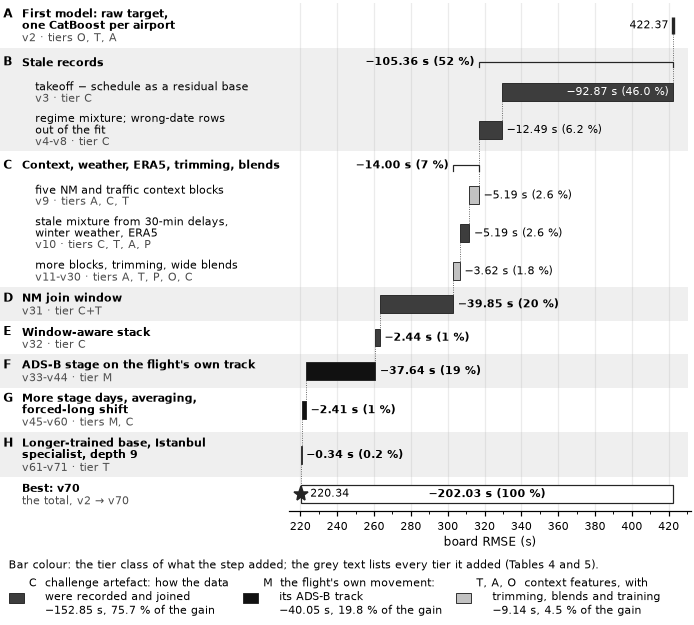

In [4]:
TABLE4 = {"B": -105.36, "C": -14.00, "D": -39.85, "E": -2.44, "F": -37.64, "G": -2.41, "H": -0.34}   # stage changes
TABLE4_TOTAL = -202.03
TABLE4_SHARE = {"B": 52, "C": 7, "D": 20, "E": 1, "F": 19, "G": 1, "H": 0.2}   # % of the total gain, as Table 4 prints
TABLE5 = {3: -92.87, 9: -5.19, 10: -5.19}      # Table 5, rows 1, 5 and 6: the board step at that upload
ART, OWN, REC = "C", "M", "TAO"                 # the colour classes: record artefacts, own movement, context features
STAGE_NAME = {"A": "First model: raw target,\none CatBoost per airport", "B": "Stale records",
              "C": "Context, weather, ERA5, trimming, blends"}
STEPS = [   # stage, first and last upload, what changed (Table 4), the tiers it added (Table 4), class
    ("B", 3, 3, "takeoff − schedule as a residual base", "C", ART),
    ("B", 4, 8, "regime mixture; wrong-date rows\nout of the fit", "C", ART),
    ("C", 9, 9, "five NM and traffic context blocks", "A, C, T", REC),
    ("C", 10, 10, "stale mixture from 30-min delays,\nwinter weather, ERA5", "C, T, A, P", ART),   # Table 5's tiers
    ("C", 11, 30, "more blocks, trimming, wide blends", "A, T, P, O, C", REC),
    ("D", 31, 31, "NM join window", "C+T", ART),
    ("E", 32, 32, "Window-aware stack", "C", ART),
    ("F", 33, 44, "ADS-B stage on the flight's own track", "M", OWN),
    ("G", 45, 60, "More stage days, averaging,\nforced-long shift", "M, C", OWN),
    ("H", 61, 71, "Longer-trained base, Istanbul\nspecialist, depth 9", "T", REC),
]
FIRST_TIERS = "O, T, A"                          # stage A, the CatBoost row: what the first model added


def best_before(v):
    return best_upto(v - 1)


WF = pd.DataFrame(STEPS, columns=["stage", "first", "last", "text", "tiers", "cls"])
WF["top"] = [best_before(a) for a in WF["first"]]          # the best score before the step
WF["end"] = [best_upto(b) for b in WF["last"]]             # the best score after it
WF["change"] = WF["end"] - WF["top"]
WF["share"] = 100 * -WF["change"] / TOT
assert np.isclose(WF["top"].iloc[0], START) and np.isclose(WF["end"].iloc[-1], FINAL_BEST), "the steps miss an end"
assert np.allclose(WF["top"].iloc[1:].to_numpy(), WF["end"].iloc[:-1].to_numpy()), "the steps do not chain"
STAGE_CHANGE = WF.groupby("stage", sort=False)["change"].sum()
for s, d in TABLE4.items():
    assert round(STAGE_CHANGE[s], 2) == d, f"stage {s}: {STAGE_CHANGE[s]:.4f} against Table 4's {d}"
    assert np.isclose(STAGE_CHANGE[s], gain[s]), f"stage {s} differs from the stage table"
    sh = 100 * -STAGE_CHANGE[s] / TOT
    assert (round(sh) if TABLE4_SHARE[s] >= 1 else round(sh, 1)) == TABLE4_SHARE[s], f"stage {s}: share {sh:.2f} %"
assert round(FINAL_BEST - START, 2) == TABLE4_TOTAL, FINAL_BEST - START
for v, d in TABLE5.items():
    assert round(best_upto(v) - best_before(v), 2) == d, f"v{v}: {best_upto(v) - best_before(v):.4f} against {d}"
print(WF.assign(versions=[f"v{a}" if a == b else f"v{a}-v{b}" for a, b in zip(WF["first"], WF["last"])])
      [["stage", "versions", "tiers", "cls", "top", "end", "change", "share"]]
      .round({"top": 4, "end": 4, "change": 4, "share": 2}).to_string(index=False))
print(f"stages: {', '.join(f'{s} {c:+.2f} s' for s, c in STAGE_CHANGE.items())}; total {FINAL_BEST - START:+.2f} s "
      f"(v{CH.v.iloc[0]} {START:.4f} -> v{VBEST} {FINAL_BEST:.4f}); all match Table 4, and v3, v9, v10 Table 5")
CLASS_CHANGE = WF.groupby("cls", sort=False)["change"].sum()      # the total gain by colour class
assert np.isclose(CLASS_CHANGE.sum(), FINAL_BEST - START)
print("by colour class:", {c: f"{d:+.2f} s ({100 * -d / TOT:.1f} %)" for c, d in CLASS_CHANGE.items()})
TABLE4_STEPS = [4, 7, 15, 20, 29, 46, 55, 60, 62, 69, 70]   # Table 4's steps inside the bars, for the record
print("best score at Table 4's steps inside the bars (change against the step before):",
      {f"v{v}": f"{best_upto(v):.2f} ({best_upto(v) - best_upto(p):+.2f})"
       for p, v in zip([3, 4, 10, 15, 20, 44, 46, 55, 60, 62, 69], TABLE4_STEPS)})

# ---- the figure: one row per level, stage header or step, top to bottom; y in inches from the figure's bottom ----
CLASS_COLOR = {ART: ps.TIER_COLORS["C"], OWN: ps.TIER_COLORS["M"], REC: ps.TIER_COLORS["T"]}
CLASS_TEXT = {ART: ps.TIER_TEXT["C"], OWN: ps.TIER_TEXT["M"], REC: ps.TIER_TEXT["T"]}
CLASS_LABEL = {ART: "C  challenge artefact: how the data\n    were recorded and joined",
               OWN: "M  the flight's own movement:\n    its ADS-B track",
               REC: "T, A, O  context features, with\n    trimming, blends and training"}
CLASS_LABEL = {c: f"{t}\n    {sg(CLASS_CHANGE[c])} s, {100 * -CLASS_CHANGE[c] / TOT:.1f} % of the gain"
               for c, t in CLASS_LABEL.items()}
INK, SHADE = "#252525", "#EFEFEF"
BAR, PAD, GAP = 0.16, 0.045, 0.012             # inches: a bar's thickness, the space around a row's text, title-detail
AXL, AXR, AXT, AXB = 2.60, 0.05, 0.03, 1.02   # inches: the plot's left edge and the margins
X_LO, X_HI = 214, 432                          # the x axis, board RMSE (s)
TITLE = {True: dict(fontsize=7.5, fontweight="bold"), False: dict(fontsize=7, fontweight="normal")}   # stage, step
DETAIL = dict(fontsize=7, color="0.3")


def vers(r):
    return f"v{r.first}" if r.first == r.last else f"v{r.first}-v{r.last}"


def tiers(t):
    return f"tier{'s' if ',' in t else ''} {t}"


def pct(sh, stage):
    # a stage's share as Table 4 prints it (whole per cent, one decimal below 1 %); a step's to one decimal
    return f"{sh:.0f} %" if stage and sh >= 1 else f"{sh:.1f} %"


ROWS = [("level", "A", STAGE_NAME["A"], f"v{CH.v.iloc[0]} · {tiers(FIRST_TIERS)}", None)]
for s, grp in WF.groupby("stage", sort=False):
    if len(grp) > 1:                          # a stage of several steps: a header with the stage's total
        ROWS.append(("header", s, STAGE_NAME[s], None, None))
        ROWS += [("step", None, r.text, f"{vers(r)} · {tiers(r.tiers)}", i) for i, r in grp.iterrows()]
    else:
        i = grp.index[0]
        ROWS.append(("stage", s, grp.at[i, "text"], f"{vers(grp.loc[i])} · {tiers(grp.at[i, 'tiers'])}", i))
ROWS.append(("total", None, f"Best: v{VBEST}", f"the total, v{CH.v.iloc[0]} → v{VBEST}", None))

MEAS = plt.figure()                           # the rows' text heights as drawn, in inches
rnd_m = MEAS.canvas.get_renderer()


def text_h(text, **kw):
    t = MEAS.text(0, 0, text, linespacing=1.0, **kw)
    h = t.get_window_extent(rnd_m).height / MEAS.dpi
    t.remove()
    return h


HT = [text_h(t, **TITLE[kind != "step"]) for kind, _, t, _, _ in ROWS]
HD = [text_h(d, **DETAIL) if d is not None else 0.0 for *_, d, _ in ROWS]
plt.close(MEAS)
BLOCK = [ht + (GAP + hd if hd else 0.0) for ht, hd in zip(HT, HD)]
PITCH = [max(b, BAR) + 2 * PAD for b in BLOCK]
H = AXT + sum(PITCH) + AXB
YC = H - AXT - (np.cumsum(PITCH) - np.array(PITCH) / 2)       # the rows' centres
fig = plt.figure(figsize=(ps.WIDTH, H))
ax = fig.add_axes([AXL / ps.WIDTH, AXB / H, (ps.WIDTH - AXL - AXR) / ps.WIDTH, (H - AXT - AXB) / H])
ax.set_xlim(X_LO, X_HI)
ax.set_ylim(AXB, H - AXT)
tr = mtransforms.blended_transform_factory(fig.dpi_scale_trans, ax.transData)     # x and y in inches
ax.patch.set_alpha(0)                                                              # the shading shows through

# the stages B, D, F and H shaded, as in fig08_01; the shading runs under the row labels too
stage_of = []
for kind, s, *_ in ROWS:
    stage_of.append(s if s else stage_of[-1] if kind == "step" else None)
for s in [s for i, (s, *_) in enumerate(STAGES) if i % 2]:
    ks = [k for k, st in enumerate(stage_of) if st == s]
    y0, y1 = YC[ks[-1]] - PITCH[ks[-1]] / 2, YC[ks[0]] + PITCH[ks[0]] / 2
    ax.add_patch(plt.Rectangle((0, y0), ps.WIDTH - AXR, y1 - y0, transform=tr, fc=SHADE, lw=0, zorder=0,
                               clip_on=False))

labels, values = [], []                 # the row labels and the value labels, checked below
for k, (kind, s, title, detail, i) in enumerate(ROWS):
    top = YC[k] + BLOCK[k] / 2               # the row's text block, centred on the row
    x_t = 0.20 if kind != "step" else 0.32
    if s:
        labels.append(ax.text(0.03, top, s, transform=tr, ha="left", va="top", fontsize=8, fontweight="bold"))
    labels.append(ax.text(x_t, top, title, transform=tr, ha="left", va="top", linespacing=1.0,
                          **TITLE[kind != "step"]))
    if detail is not None:
        labels.append(ax.text(x_t, top - HT[k] - GAP, detail, transform=tr, ha="left", va="top", linespacing=1.0,
                              **DETAIL))


def value_label(x_right, x_left, y, text, cls, bold):
    # right of the bar; the checks below move it inside the bar, right-aligned, where the axis ends first
    t = ax.text(x_right + 2.5, y, text, ha="left", va="center", fontsize=7, fontweight="bold" if bold else "normal",
                zorder=6)
    values.append([t, False, x_left, x_right, cls])


connect = []                            # (x, y of the row above, y of the row below) for the dotted connectors
prev = None
for k, (kind, s, title, detail, i) in enumerate(ROWS):
    y = YC[k]
    if kind == "level":
        ax.plot([START, START], [y - BAR / 2, y + BAR / 2], color=INK, lw=2.2, solid_capstyle="butt", zorder=4)
        values.append([ax.text(START - 2.5, y, f"{START:.2f}", ha="right", va="center", fontsize=7, zorder=6),
                       False, None, None, None])
        prev = (START, y)
    elif kind == "header":                 # a bracket over the stage's span, with its total
        grp = WF[WF["stage"].eq(s)]
        x0, x1 = grp["end"].iloc[-1], grp["top"].iloc[0]
        ax.plot([x0, x0, x1, x1], [y - 0.05, y, y, y - 0.05], color=INK, lw=0.8, zorder=4, solid_joinstyle="miter")
        values.append([ax.text(x0 - 2.5, y, f"{sg(STAGE_CHANGE[s])} s ({pct(100 * -STAGE_CHANGE[s] / TOT, True)})",
                               ha="right", va="center", fontsize=7, fontweight="bold", zorder=6),
                       False, None, None, None])
    elif kind in ("step", "stage"):
        r = WF.loc[i]
        ax.barh(y, r.top - r.end, left=r.end, height=BAR, color=CLASS_COLOR[r.cls], ec=INK, lw=0.6, zorder=3)
        value_label(r.top, r.end, y, f"{sg(r.change)} s ({pct(r.share, kind == 'stage')})", r.cls, kind == "stage")
        connect.append((r.top, prev[1], y))
        prev = (r.end, y)
    else:                                  # the total: v2 to v70, and the best score
        ax.barh(y, START - FINAL_BEST, left=FINAL_BEST, height=BAR, color="white", ec=INK, lw=0.8, zorder=3)
        ax.plot(FINAL_BEST, y, "*", ms=10, color=INK, zorder=5)
        values.append([ax.text(FINAL_BEST + 5, y, f"{FINAL_BEST:.2f}", ha="left", va="center", fontsize=7,
                               zorder=6), False, None, None, None])
        values.append([ax.text((FINAL_BEST + START) / 2, y, f"{sg(FINAL_BEST - START)} s (100 %)", ha="center",
                               va="center", fontsize=7, fontweight="bold", zorder=6), False, None, None, None])
        connect.append((FINAL_BEST, prev[1], y))
for x, ya, yb in connect:                  # from the bar above down to the next, at the level they share
    ax.plot([x, x], [ya - BAR / 2, yb + BAR / 2], color="0.35", lw=0.6, ls=(0, (1, 1.5)), zorder=2)

ax.set_xticks(range(220, X_HI, 20))
ax.set_xticks(range(220, X_HI, 10), minor=True)
ax.set_xlabel("board RMSE (s)", labelpad=2)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", left=False, labelleft=False)
handles = [plt.Rectangle((0, 0), 1, 1, fc=CLASS_COLOR[c], ec=INK, lw=0.6) for c in (ART, OWN, REC)]
leg = fig.legend(handles, [CLASS_LABEL[c] for c in (ART, OWN, REC)], loc="lower left", ncols=3, fontsize=7,
                 frameon=False, bbox_to_anchor=(0.0, 0.0), borderaxespad=0.1, handlelength=1.4, handleheight=1.1,
                 columnspacing=1.3, handletextpad=0.5, title_fontsize=7, alignment="left",
                 title="Bar colour: the tier class of what the step added; the grey text lists every tier it added "
                       "(Tables 4 and 5).")

# layout checks: the row labels left of the plot, every value label inside the axis and clear of its bar, no overlaps
fig.canvas.draw()
rnd = fig.canvas.get_renderer()
pt = fig.dpi / 72
ax_box = ax.get_window_extent(rnd)
for v in values:                            # a step's label that leaves the axis on the right goes inside its bar
    t, _, xl, xr, cls = v
    if xl is not None and t.get_window_extent(rnd).x1 > ax_box.x1:
        t.set_x(xr - 2.5)
        t.set_horizontalalignment("right")
        t.set_color(CLASS_TEXT[cls])
        v[1] = True
fig.canvas.draw()
long_ = [(t.get_text(), round(t.get_window_extent(rnd).x1 / fig.dpi, 2)) for t in labels
         if t.get_window_extent(rnd).x1 > ax_box.x0 - 2 * pt]
assert not long_, f"row labels that reach into the plot (right edge in inches; the plot starts at {AXL}): {long_}"
bad = []
for t, inside, xl, xr, _ in values:
    b = t.get_window_extent(rnd)
    if b.x0 < ax_box.x0 or b.x1 > ax_box.x1:
        bad.append((t.get_text(), "leaves the axis"))
    if inside:                              # inside its bar, with a point to spare at the left
        if b.x0 < ax.transData.transform((xl, 0))[0] + pt:
            bad.append((t.get_text(), "does not fit its bar"))
assert not bad, bad
ext = [(t.get_text(), t.get_window_extent(rnd)) for t in labels + [v[0] for v in values]]
clash = [(a, b) for i, (a, ea) in enumerate(ext) for b, eb in ext[i + 1:] if ea.overlaps(eb)]
assert not clash, clash
below = min(b.y0 for b in [ax.xaxis.label.get_window_extent(rnd)]
            + [t.get_window_extent(rnd) for t in ax.get_xticklabels() if t.get_text()])
lg_box = leg.get_window_extent(rnd)
assert lg_box.y1 < below - pt, (f"the legend ({lg_box.y0 / fig.dpi:.2f}-{lg_box.y1 / fig.dpi:.2f} in) reaches the "
                                f"x axis (its lowest text at {below / fig.dpi:.2f} in)")
tight = fig.get_tightbbox(rnd)
assert tight.x0 >= -0.01 and tight.x1 <= ps.WIDTH + 0.01, f"the figure spills beyond {ps.WIDTH} in: {tight}"
print(f"{len(ROWS)} rows, {len(WF)} bars; figure {tight.width:.2f} x {tight.height:.2f} in")
ps.save(fig, "fig08_04_board_waterfall")
plt.show()

# Part 2. The operational models

Two figures for `docs/report.md`, Part 2. The operational models predict before the aircraft moves, each at a fixed
moment:
- 24 h and 3 h before the scheduled off-block (SOBT), for planning; runway-blind, because the runway is not known
  hours ahead;
- H1, 15 min before the last filed off-block time (IOBT, else LOBT, else SOBT): the headline, F1 (`op_h1_f1_plan`)
  since 13 October;
- H0, at the flight's own recorded off-block: a comparison on 2025 only, because 2026 blanks the off-blocks.

**Inputs.** Two tracked files that the lab scripts write; no model is trained and no data frame is read.
- `docs/operational_features.csv`, the input catalogue (`python lab/feature_catalogue.py`): every column of every
  member, with its family and its tier at that member's moment. The members are the four configurations of the
  moments (`hl24`, `hl3`, `h1`, `h0`) and, for the concept files, the columns they read beyond F1 (`concept` = F5,
  `concept_delivered` = the `h1f` file). fig08_02 takes the state of every cell of the four moments from it.
- `docs/operational_ladder.csv`, the operational ladder (`python lab/op_ladder_report.py`): every row's metrics per
  population on the January and July 2025 holdout. fig08_03 takes every score from it.

**Tiers** (the catalogue's and `docs/report.md`'s): O known at the moment; O* known under an assumption the data
cannot check (the planned runway is the recorded one; hours ahead the stand plan is final; at H1 the last filed
off-block times are known, the flight's own 15 min ahead and the other flights' for the next hour; other flights'
recorded runway and stand stand in for their planned ones); F planned in the concept, realised in the challenge data
(an upper bound); and for the post-operations model T (anchored on the actual takeoff), A (after the off-block), P
(published later), M (the flight's own movement in ADS-B), C (challenge artefact).

In [5]:
from matplotlib.patches import FancyBboxPatch, Patch

CATALOGUE = pd.read_csv(paths.ROOT / "docs" / "operational_features.csv")
MEMBERS = ["hl24", "hl3", "h1", "h0"]                  # the moments' configurations, in the order of the timeline
CONCEPT = ["concept", "concept_delivered"]             # F5 and the h1f file: their columns beyond F1 only
print(CATALOGUE.groupby("member").agg(config=("config", "first"), columns=("column", "size"))
      .reindex(MEMBERS + CONCEPT).to_string())

# the figure's rows: key, bold title, description, and the catalogue families each row groups
WINDOW_ROWS = [
    ("record", "Own flight record", "schedule, aircraft type,\noperator, destination",
     ["airport", "aircraft", "operation", "operator", "destination", "calendar"]),
    ("plan", "Own planned off-block", "the last filed plan (NM)", ["planned_delay"]),
    ("stand", "Own stand", "", ["stand", "stand_position"]),
    ("runway", "Own departure runway", "", ["runway", "runway_distance", "route"]),
    ("wx", "Weather", "METAR and TAF", ["metar_now", "metar_recent", "taf"]),
    ("nm", "Other flights' NM readings", "taxi-outs and push delays\nof departed flights",
     ["nm_history_short", "nm_history_long"]),
    ("live", "The airport's live state", "others' takeoffs, landings,\ntaxi-ins, runways in use",
     ["traffic_counts", "runway_use", "arrival_anomaly", "turnaround"]),
    ("plans", "Other flights' plans", "scheduled or filed, not yet\nairborne",
     ["scheduled_demand", "fut_plan", "plan_backlog"]),
    ("future", "Planning systems' plans", "AMAN, DMAN, A-SMGCS after\nthe moment: not in the data",
     ["fut_records", "fut_nm", "fut_adsb"]),
    ("after", "Only after the flight", "own takeoff and ADS-B track,\njoin window, stale records", []),
]
unmapped = set(CATALOGUE["family"]) - {f for *_, fams in WINDOW_ROWS for f in fams}
# the public ADS-B picture of the other aircraft before the moment: read by F5 and the lab rung R6, by no moment
assert unmapped <= {"adsb_now"}, unmapped
assert not CATALOGUE["member"].isin(MEMBERS)[CATALOGUE["family"].eq("adsb_now")].any()
assert not CATALOGUE.loc[CATALOGUE["member"].eq("h1"), "tier"].str.startswith("F").any(), "F1 reads a tier F input"


def cell_state(tiers, row):
    # F where any input is tier F; O* where any input rests on an assumption; else O. Outside the runway row the own
    # runway's assumption is not counted again: the counts per own runway inherit it from that row.
    if not tiers:
        return None
    if any(t.startswith("F") for t in tiers):
        return "F"
    star = [t for t in tiers if t.startswith("O*") and (row == "runway" or t != "O* (own runway)")]
    return "O*" if star else "O"


DERIVED, NCOLS = {}, {}
for m in MEMBERS + CONCEPT:
    sub = CATALOGUE[CATALOGUE["member"].eq(m)]
    for k, _, _, fams in WINDOW_ROWS:
        rows_k = sub[sub["family"].isin(fams)]
        DERIVED[(k, m)] = cell_state(sorted(set(rows_k["tier"])), k)
        NCOLS[(k, m)] = len(rows_k)
print(pd.DataFrame({m: {k: f"{DERIVED[(k, m)] or '-'} ({NCOLS[(k, m)]})" for k, *_ in WINDOW_ROWS}
                    for m in MEMBERS + CONCEPT}).to_string())
print("tiers of the cells drawn as O* (own-runway tiers left out outside the runway row):")
for m in MEMBERS:
    sub = CATALOGUE[CATALOGUE["member"].eq(m)]
    for k, _, _, fams in WINDOW_ROWS:
        if DERIVED[(k, m)] == "O*":
            t = sorted(set(sub.loc[sub["family"].isin(fams), "tier"]) - {"O", "C (NM join level)"})
            print(f"  {m:5s} {k:7s} {'; '.join(t)}")

                                     config  columns
member                                              
hl24               op_hl24_r3_rwyblind.yaml       78
hl3                 op_hl3_r4_rwyblind.yaml       86
h1                       op_h1_f1_plan.yaml      131
h0                      op_h0_r4_nodoy.yaml      118
concept                  op_h1_f5_full.yaml      169
concept_delivered   op_h1_f4_nodepthru.yaml       27
           hl24      hl3       h1       h0  concept concept_delivered
record   O (22)   O (22)   O (22)   O (22)    - (0)             - (0)
plan      - (0)    - (0)   O* (1)    O (3)    - (0)             - (0)
stand   O* (12)  O* (12)   O (11)   O (11)    - (0)             - (0)
runway    - (0)    - (0)  O* (11)  O* (11)    - (0)             - (0)
wx       O (36)   O (36)   O (37)   O (37)    - (0)             - (0)
nm        - (0)    O (8)   O (12)   O (12)    - (0)             - (0)
live      - (0)    - (0)   O (19)   O (19)    - (0)             - (0)
plans    O* (8) 

## The prediction windows and the data each can read (fig08_02, report Part 2.1)

The top band is the timeline of one departure, not to scale: the four moments of prediction, then the takeoff, after
which the post-operations model reads the whole record. The grid below gives, per moment, what the model of that
moment knows.
- **The four moments' cells** take their state from the catalogue. A cell is O* (hatched) when any input of the row's
  families that the moment's configuration reads rests on an assumption, O when none does, and empty when the
  configuration reads none of them. The catalogue's tier C, the NM-join level of the flight-plan columns, counts as O
  here: it is constant on the population the models are read on. Outside the runway row, the counts per own runway
  (weather, NM readings, live state) inherit the runway's assumption and are not marked again. The cell text and the
  reason for an empty cell are written by hand; the cell below checks every hand-written state against the catalogue.
- **Empty cells** are of two kinds: "not known yet" (dashed) and "known, not read" (solid grey: the NM history a day
  ahead, which rule R dropped because it adds nothing; findings 10.35).
- **The concept row.** The planning systems' plans after the moment (AMAN, DMAN, A-SMGCS) are not in the data. The
  tier F concept files read the other flights' realised traffic after H1 in their place, an upper bound (findings
  10.36, 10.37). F1, the H1 deliverable, reads only their plans (the row above).
- **The post-operations column** follows `docs/feature_table.md` and Part 1: the post-operations model reads the
  record after the takeoff, anchored on it, for post-operations analysis. Its decisive inputs, the flight's own
  takeoff (T), its own ADS-B track (M), the NM join window and the stale and wrong-date regimes (C), exist only after
  the flight.

Two durations on the timeline are constants from the documents: the median time from the H1 anchor to the recorded
off-block, 19.2 min on the OP rows of 2025 (`docs/operational_model.md`, section 1), and the median 2025 target,
912 s (`docs/report.md`, Table 3). The cell checks that no text leaves its box and that no two header texts overlap.

46 boxed cells and 19 header texts placed without overlap; figure 6.30 x 6.06 in


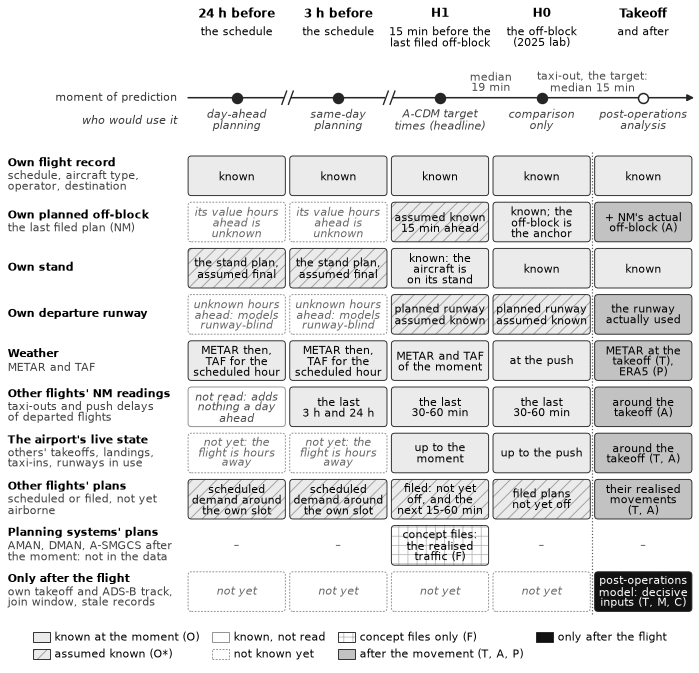

In [6]:
PUSH_AFTER_H1_MIN = 19.2   # median recorded off-block minus the H1 anchor, OP rows of 2025 (operational_model.md, 1)
TAXI_MEDIAN_S = 912        # median 2025 target (report.md, Table 3)

NA, NOTREAD, AFTER, NONE = "not yet", "not read", "after", "none"
CELLS = {   # per row: (state, text) for 24 h, 3 h, H1, H0 and the post-operations model's column
    "record": [("O", "known")] * 5,
    "plan": [(NA, "its value hours\nahead is\nunknown")] * 2
    + [("O*", "assumed known\n15 min ahead"), ("O", "known; the\noff-block is\nthe anchor"),
       (AFTER, "+ NM's actual\noff-block (A)")],
    "stand": [("O*", "the stand plan,\nassumed final")] * 2
    + [("O", "known: the\naircraft is\non its stand"), ("O", "known"), ("O", "known")],
    "runway": [(NA, "unknown hours\nahead: models\nrunway-blind")] * 2 + [("O*", "planned runway\nassumed known")] * 2
    + [(AFTER, "the runway\nactually used")],
    "wx": [("O", "METAR then,\nTAF for the\nscheduled hour")] * 2
    + [("O", "METAR and TAF\nof the moment"), ("O", "at the push"), (AFTER, "METAR at the\ntakeoff (T),\nERA5 (P)")],
    "nm": [(NOTREAD, "not read: adds\nnothing a day\nahead"), ("O", "the last\n3 h and 24 h")]
    + [("O", "the last\n30-60 min")] * 2 + [(AFTER, "around the\ntakeoff (A)")],
    "live": [(NA, "not yet: the\nflight is hours\naway")] * 2
    + [("O", "up to the\nmoment"), ("O", "up to the push"), (AFTER, "around the\ntakeoff (T, A)")],
    "plans": [("O*", "scheduled\ndemand around\nthe own slot")] * 2
    + [("O*", "filed: not yet\noff, and the\nnext 15-60 min"), ("O*", "filed plans\nnot yet off"),
       (AFTER, "their realised\nmovements\n(T, A)")],
    "future": [(NONE, "–")] * 2 + [("F", "concept files:\nthe realised\ntraffic (F)"), (NONE, "–"), (NONE, "–")],
    "after": [(NA, "not yet")] * 4 + [("M", "post-operations\nmodel: decisive\ninputs (T, M, C)")],
}
for k, *_ in WINDOW_ROWS:                  # every hand-written state of the four moments against the catalogue
    for j, m in enumerate(MEMBERS):
        st, d = CELLS[k][j][0], DERIVED[(k, m)]
        if st == "F":
            assert d is None and all(DERIVED[(k, c)] == "F" for c in CONCEPT), (k, m)
        elif st in (NA, NOTREAD, NONE):
            assert d is None, (k, m, d)
        else:
            assert d == st, (k, m, st, d)

MOMENTS = [("24 h before", "the schedule", "day-ahead\nplanning"),
           ("3 h before", "the schedule", "same-day\nplanning"),
           ("H1", "15 min before the\nlast filed off-block", "A-CDM target\ntimes (headline)"),
           ("H0", "the off-block\n(2025 lab)", "comparison\nonly"),
           ("Takeoff", "and after", "post-operations\nanalysis")]
TC = ps.TIER_COLORS
FILL = {"O": TC["O"], "O*": TC["O"], "F": "white", AFTER: TC["T"], "M": TC["M"], NA: "white", NOTREAD: "white"}
HATCH = {"O*": "///", "F": "++"}
TEXT_COLOR = {"M": "white", NA: "0.4", NOTREAD: "0.3", NONE: "0.4"}
INK, GREY_EDGE = "#252525", "0.55"
HATCH_INK = {"O*": "0.62", "F": "0.75"}

W = ps.WIDTH
X0, NCOL = 1.66, 5                         # inches: the left edge of the first column; columns
CW = (W - X0 - 0.02) / NCOL
RH, HEAD, LEGH = 0.42, 1.36, 0.50          # row height, timeline band, legend band
H = HEAD + RH * len(WINDOW_ROWS) + LEGH
fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([0, 0, 1, 1])            # data units are inches
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.axis("off")
cx = [X0 + CW * (i + 0.5) for i in range(NCOL)]
header = []                                 # header texts, checked for overlaps below

# the timeline of one departure (not to scale)
YL = H - 0.86
ax.annotate("", xy=(W - 0.02, YL), xytext=(X0 + 0.02, YL), zorder=2,
            arrowprops=dict(arrowstyle="-|>", lw=1.0, color=INK, mutation_scale=9, shrinkA=0, shrinkB=0))
for i, (t1, t2, role) in enumerate(MOMENTS):
    ax.plot(cx[i], YL, "o", ms=6.5, mfc=INK if i < 4 else "white", mec=INK, mew=1.0, zorder=5)
    header += [ax.text(cx[i], H - 0.04, t1, ha="center", va="top", fontsize=8, fontweight="bold"),
               ax.text(cx[i], H - 0.20, t2, ha="center", va="top", fontsize=7, linespacing=1.05),
               ax.text(cx[i], YL - 0.10, role, ha="center", va="top", fontsize=7, style="italic", color="0.25",
                       linespacing=1.05)]
for i in (0, 1):                            # break marks: hours, not minutes, lie between these moments
    xm = (cx[i] + cx[i + 1]) / 2
    ax.plot([xm - 0.035, xm + 0.035], [YL, YL], color="white", lw=2.5, zorder=3, solid_capstyle="butt")
    for dx in (-0.03, 0.03):
        ax.plot([xm + dx - 0.022, xm + dx + 0.022], [YL - 0.06, YL + 0.06], color=INK, lw=0.9, zorder=4)
header += [ax.text((cx[2] + cx[3]) / 2, YL + 0.05, f"median\n{PUSH_AFTER_H1_MIN:.0f} min", ha="center", va="bottom",
                   fontsize=7, color="0.3", linespacing=1.0),
           ax.text((cx[3] + cx[4]) / 2, YL + 0.05, f"taxi-out, the target:\nmedian {TAXI_MEDIAN_S / 60:.0f} min",
                   ha="center", va="bottom", fontsize=7, color="0.3", linespacing=1.0),
           ax.text(X0 - 0.08, YL, "moment of prediction", ha="right", va="center", fontsize=7.5, color="0.2"),
           ax.text(X0 - 0.08, YL - 0.21, "who would use it", ha="right", va="center", fontsize=7.5, color="0.2",
                   style="italic")]

# the grid
Y0 = H - HEAD
LINE_B, LINE_D = 0.118, 0.110               # inches per line: the bold title, the description
labels, boxed = [], []                       # (row label texts), (text, box) pairs, checked below
for r, (k, title, desc, _) in enumerate(WINDOW_ROWS):
    yt = Y0 - r * RH
    nd = desc.count("\n") + 1 if desc else 0
    top = yt - RH / 2 + (LINE_B + nd * LINE_D) / 2
    labels.append(ax.text(0.04, top, title, ha="left", va="top", fontsize=7.5, fontweight="bold"))
    if desc:
        labels.append(ax.text(0.04, top - LINE_B, desc, ha="left", va="top", fontsize=7, color="0.25",
                              linespacing=1.0))
    for i in range(NCOL):
        st, txt = CELLS[k][i]
        x0, y0, w, h = X0 + CW * i + 0.02, yt - RH + 0.03, CW - 0.04, RH - 0.06
        t = ax.text(x0 + w / 2, y0 + h / 2, txt, ha="center", va="center", fontsize=7, linespacing=1.0, zorder=4,
                    color=TEXT_COLOR.get(st, "black"), style="italic" if st in (NA, NOTREAD) else "normal")
        if st == NONE:                       # not in the data, not read: no box
            continue
        b = FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0,rounding_size=0.03", fc=FILL[st],
                           ec=GREY_EDGE if st in (NA, NOTREAD) else INK, lw=0.6, ls=(0, (2, 1.5)) if st == NA else "-",
                           hatch=HATCH.get(st), hatchcolor=HATCH_INK.get(st), zorder=2)
        ax.add_patch(b)
        boxed.append((t, b))
xs = X0 + CW * 4                             # the four moments | the post-operations model
ax.plot([xs, xs], [Y0 - RH * len(WINDOW_ROWS) + 0.01, Y0 + 0.02], color="0.35", lw=0.8, ls=(0, (1, 1.6)), zorder=1)

LEGEND = [(Patch(fc=FILL["O"], ec=INK, lw=0.6), "known at the moment (O)"),
          (Patch(fc=FILL["O*"], ec=INK, lw=0.6, hatch=HATCH["O*"], hatchcolor=HATCH_INK["O*"]), "assumed known (O*)"),
          (Patch(fc="white", ec=GREY_EDGE, lw=0.6), "known, not read"),
          (Patch(fc="white", ec=GREY_EDGE, lw=0.6, ls=(0, (2, 1.5))), "not known yet"),
          (Patch(fc="white", ec=INK, lw=0.6, hatch=HATCH["F"], hatchcolor=HATCH_INK["F"]), "concept files only (F)"),
          (Patch(fc=FILL[AFTER], ec=INK, lw=0.6), "after the movement (T, A, P)"),
          (Patch(fc=FILL["M"], ec=INK, lw=0.6), "only after the flight")]
leg = fig.legend([p for p, _ in LEGEND], [s for _, s in LEGEND], loc="lower center", ncols=4, fontsize=7,
                 frameon=False, bbox_to_anchor=(0.5, 0.0), handlelength=1.6, handleheight=1.0, columnspacing=1.2,
                 handletextpad=0.4)

# layout checks: every cell text inside its box, the row labels left of the grid, no two header texts overlapping
fig.canvas.draw()
rnd = fig.canvas.get_renderer()
pt = fig.dpi / 72                            # display units per point
bad = []
for t, b in boxed:                           # the room to spare on the tightest side, in points (at least one)
    tb, bb = t.get_window_extent(rnd), b.get_window_extent(rnd)
    room = min(tb.x0 - bb.x0, bb.x1 - tb.x1, tb.y0 - bb.y0, bb.y1 - tb.y1) / pt
    if room < 1.0:
        bad.append((t.get_text(), round(room, 1)))
assert not bad, f"texts that leave their box (room in pt): {bad}"
pad = pt
grid_x0 = min(b.get_window_extent(rnd).x0 for _, b in boxed)
assert max(t.get_window_extent(rnd).x1 for t in labels) < grid_x0 - pad, "a row label reaches into the grid"
ext = [t.get_window_extent(rnd) for t in header]
clash = [(header[i].get_text(), header[j].get_text()) for i in range(len(ext)) for j in range(i + 1, len(ext))
         if ext[i].overlaps(ext[j])]
assert not clash, clash
tight = fig.get_tightbbox(rnd)               # inches: the saved figure keeps the print width
assert tight.x0 >= -0.01 and tight.x1 <= W + 0.01, f"the figure spills beyond {W} in: {tight}"
print(f"{len(boxed)} boxed cells and {len(header)} header texts placed without overlap; "
      f"figure {tight.width:.2f} x {tight.height:.2f} in")
ps.save(fig, "fig08_02_windows")
plt.show()

## The scores by window, beside the post-operations models (fig08_03, report Part 2.2)

Every value is read from `docs/operational_ladder.csv` (rows `slice == "all"`), on the January and July 2025
holdout; each model was fitted on the other ten months of 2025.
- **Populations.** *OP*: the NM-matched departures with a target below 1 h (338,277 of 344,419, 98.2 %). It leaves out
  the long stale records and the wrong-date records, the other targets above 1 h and the departures without an NM
  flight. *ALL*: every holdout departure, the population the board's RMSE runs over.
- **Why OP is the "RMSE without the long stale records".** The operational models are fitted without targets above
  2 h and without wrong-date records, and OP leaves out every target of an hour or more and the departures without an
  NM flight, where the long stale records sit. It filters on the target and the NM match, not on a stale label, so the
  shorter stale records stay in the fit and in OP, for every model alike (report Part 2.2: by C1's regime labels,
  1,621 of the 1,988 stale-labelled holdout departures lie inside OP and carry 5.7 % of F1's OP squared error).
- **The rows.** `D-24H`, `D-3H`: the means of the 24 h and 3 h deliverables (two seeds each); `D-H1`: F1's mean (three
  seeds); `D-H1-MAE`: the median the H1 file ships, rule M's member clamped into the calibrated P10-P90 band;
  `op_h0_r4_nodoy`: H0, seed 42, the inputs of the H1 deliverable until 13 October at the push, plus the push's delay
  against the plan and the schedule. The post-operations models: C1, the base member exp066 without ADS-B; C3, v62,
  with the flight's own ADS-B track (the ladder's reconstruction; v70 differs from it by tenths of a second).
- **H0 has no ALL score.** On a stale record its anchor, the recorded off-block, is the schedule, so the ladder scores
  H0 on OP only.
- **The shading** follows fig08_02: light for what is known before the movement, dark for the post-operations models,
  whose decisive inputs exist only after the flight (C: the join window and the record regimes; M: the own ADS-B
  track). Each panel gives the ratio of H1's mean to C1.

                  n_OP OP MAE OP RMSE   n_ALL ALL RMSE
D-24H           338277 218.19  321.60  344419   610.98
D-3H            338277 214.52  312.83  344419   606.21
D-H1            338277 184.29  276.27  344419   583.50
D-H1-MAE        338277 178.76  281.14  344419   594.29
op_h0_r4_nodoy  338277 178.22  265.42    <NA>      NaN
C1              338277 137.06  203.16  344419   313.99
C3              338277 103.94  174.82  344419   294.13
  D-24H           2026-10-11T15-57-44__op_hl24_r3_rwyblind__930c7b15__s42, 2026-10-11T16-13-52__op_hl24_r3_rwyblind__930c7b15__s43
  D-3H            2026-10-11T15-20-52__op_hl3_r4_rwyblind__c93d69e3__s42, 2026-10-11T15-38-22__op_hl3_r4_rwyblind__c93d69e3__s43
  D-H1            2026-10-13T06-12-27__op_h1_f1_plan__40ac5f36__s42, 2026-10-13T07-14-31__op_h1_f1_plan__40ac5f36__s43, 2026-10-13T07-54-55__op_h1_f1_plan__40ac5f36__s44
  D-H1-MAE        2026-10-13T10-24-22__op_h1_f1_plan_mae_exact_cpu__d7b90aac__s42
  op_h0_r4_nodoy  2026-10-11T18-59-51__op_h0_r4_

figure 6.06 x 3.06 in


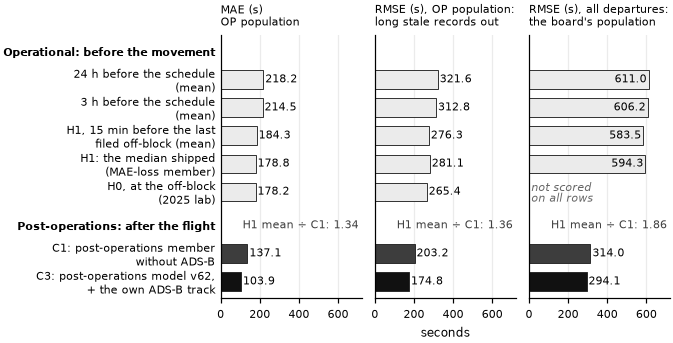

In [7]:
INK = "#252525"
LADDER = pd.read_csv(paths.ROOT / "docs" / "operational_ladder.csv")
LA = LADDER[LADDER["slice"].eq("all") & LADDER["level"].eq("all")]
SCORE_ROWS = [("D-24H", "24 h before the schedule", "(mean)", "O"),
              ("D-3H", "3 h before the schedule", "(mean)", "O"),
              ("D-H1", "H1, 15 min before the last", "filed off-block (mean)", "O"),
              ("D-H1-MAE", "H1: the median shipped", "(MAE-loss member)", "O"),
              ("op_h0_r4_nodoy", "H0, at the off-block", "(2025 lab)", "O"),
              ("C1", "C1: post-operations member", "without ADS-B", "C"),
              ("C3", "C3: post-operations model v62,", "+ the own ADS-B track", "M")]
sc = {}
for key, *_ in SCORE_ROWS:
    r = LA[LA["row"].eq(key)].set_index("population")
    assert "OP" in r.index, key
    sc[key] = {"run": r.at["OP", "run_id"], "n_OP": int(r.at["OP", "n"]), "OP MAE": r.at["OP", "mae"],
               "OP RMSE": r.at["OP", "rmse"], "n_ALL": int(r.at["ALL", "n"]) if "ALL" in r.index else pd.NA,
               "ALL RMSE": r.at["ALL", "rmse"] if "ALL" in r.index else np.nan}
SC = pd.DataFrame(sc).T
assert SC["n_OP"].nunique() == 1 and SC["n_ALL"].dropna().nunique() == 1, "the rows are not on the same population"
print(SC.drop(columns="run").to_string(float_format=lambda v: f"{v:.2f}"))
for k, v in SC["run"].items():
    print(f"  {k:15s} {v}")
METRICS = [("OP MAE", "MAE (s)", "OP population"),
           ("OP RMSE", "RMSE (s), OP population:", "long stale records out"),
           ("ALL RMSE", "RMSE (s), all departures:", "the board's population")]
ratio = {m: float(SC.at["D-H1", m] / SC.at["C1", m]) for m, *_ in METRICS}
print("H1 mean / C1:", {m: round(v, 2) for m, v in ratio.items()},
      "| H1 mean - C1 (s):", {m: round(float(SC.at["D-H1", m] - SC.at["C1", m]), 1) for m, *_ in METRICS})

YS = [1, 2, 3, 4, 5, 7.2, 8.2]
XMAX = 720                                   # one shared x axis: the panels compare by eye
GROUPS = [(0, "Operational: before the movement"), (6.2, "Post-operations: after the flight")]
fig, axes = plt.subplots(1, 3, figsize=(ps.WIDTH, 3.3), sharey=True, sharex=True)
values, titles = [], []                      # value labels and panel titles, checked below
for ax, (m, t1, t2) in zip(axes, METRICS):
    for y, (key, _, _, tier) in zip(YS, SCORE_ROWS):
        v = SC.at[key, m]
        if not np.isfinite(v):
            ax.text(12, y, "not scored\non all rows", va="center", ha="left", fontsize=7, color="0.4",
                    style="italic", linespacing=1.0)
            continue
        ax.barh(y, v, height=0.66, color=ps.TIER_COLORS[tier], ec=INK, lw=0.6)
        inside = v > 0.7 * XMAX                  # a long bar carries its value inside its end
        values.append((ax, ax.text(v - 10 if inside else v + 10, y, f"{v:.1f}", va="center",
                                   ha="right" if inside else "left", fontsize=7,
                                   color=ps.TIER_TEXT[tier] if inside else "black")))
    ax.text(XMAX - 15, GROUPS[1][0], f"H1 mean ÷ C1: {ratio[m]:.2f}", ha="right", va="center", fontsize=7,
            color="0.25")
    titles.append(ax.set_title(f"{t1}\n{t2}", fontsize=7.5, loc="left", linespacing=1.1))
    ax.set_xlim(0, XMAX)
    ax.set_xticks([0, 200, 400, 600])
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)                   # the grid behind the bars
ticks = [(y, f"{a}\n{b}") for y, (_, a, b, _) in zip(YS, SCORE_ROWS)] + GROUPS
axes[0].set_yticks([y for y, _ in ticks], [s for _, s in ticks], fontsize=7)
for lab_, (y, _) in zip(axes[0].get_yticklabels(), ticks):
    if (y, lab_.get_text()) in GROUPS:
        lab_.set_fontweight("bold")
        lab_.set_fontsize(7.5)
for ax in axes:
    ax.tick_params(axis="y", length=0)
axes[0].set_ylim(8.8, -0.6)
axes[1].set_xlabel("seconds")
fig.tight_layout(w_pad=0.8)
fig.canvas.draw()
rnd = fig.canvas.get_renderer()
for ax, t in values:                          # every value label inside its panel
    assert t.get_window_extent(rnd).x1 <= ax.get_window_extent(rnd).x1, t.get_text()
for a, b in zip(titles, titles[1:]):          # the panel titles side by side, not overlapping
    assert a.get_window_extent(rnd).x1 < b.get_window_extent(rnd).x0, (a.get_text(), b.get_text())
tight = fig.get_tightbbox(rnd)
assert tight.x0 >= -0.01 and tight.x1 <= ps.WIDTH + 0.01, f"the figure spills beyond {ps.WIDTH} in: {tight}"
print(f"figure {tight.width:.2f} x {tight.height:.2f} in")
ps.save(fig, "fig08_03_scores_by_window")
plt.show()